# Conjunto A — cancelamento tardio e decisão por reserva

## Cinco decisões, antes de qualquer import

| Decisão | Definição |
|---|---|
| Unidade de análise | Uma reserva do City Hotel; a decisão se refere à primeira noite |
| Instante da decisão | Início do dia de chegada, após fechar os registros da véspera |
| Janela de observação | Atributos disponíveis até a véspera e histórico anterior; nenhum status final como preditor |
| Janela de desempenho | Cancelamento ou não comparecimento no dia de chegada |
| População elegível | Reservas feitas antes da chegada, com 1 a 14 noites planejadas e ainda ativas ao fechar a véspera |

## Negócio, dois custos e hipóteses

Você quer decidir se oferece novamente a primeira noite de uma reserva ativa,
apostando que o titular não chegará. `y=1` significa cancelamento na chegada ou
no-show. Cancelamentos já conhecidos antes disso saem da população: não há
incerteza a prever nesses casos.

| Ação e desfecho | Titular chega (`y=0`) | Titular não chega (`y=1`) |
|---|---:|---:|
| Não revender | R$ 0 de perda incremental | R$ 400: oportunidade perdida |
| Revender | R$ 1.200: acomodação e compensação | R$ 0 de perda incremental |

São **custos hipotéticos em reais**, inspirados no enunciado, não preços
observados em Portugal. A simulação pressupõe procura substituta suficiente,
uma reserva representando uma vaga de primeira noite e os demais custos iguais.
Não temos capacidade real do hotel, inventário por tipo de quarto, penalidades
cobradas, efetividade da revenda ou receita contrafactual. Portanto avaliamos
**perda incremental sob hipóteses**, não lucro real nem autorização operacional
para praticar overbooking. As demais noites não fazem parte desta perda.

Revender custa em esperança `1.200 × (1-p)`; não revender custa `400 × p`.
Revenda se `p ≥ 1.200 / (1.200 + 400) = 0,75` (no empate, as ações equivalem).
O custo alto de prejudicar quem chega exige uma probabilidade elevada.

## Fontes e execução

- [Enunciado](../fontes/TRABALHO_extraclasse.pdf).
- Antonio, Almeida e Nunes (2019), [artigo original](https://doi.org/10.1016/j.dib.2018.11.126).
- [TidyTuesday, 11/02/2020](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-02-11), espelho dos dados e dicionário.
- Cópias e metadados em `../fontes/` e `../dados/proveniencia.json`.
- Rotinas compartilhadas auditáveis: [metodo.py](../src/metodo.py). Não é necessário executar outro notebook antes deste.
- Dependências: `../requirements.txt`; instruções locais: `../COMO_EXECUTAR.md`.

O artigo é distribuído sob CC BY. O espelho atribui os dados aos autores;
não presumimos uma licença CC0 independente. Consulte a documentação preservada
para atribuição e condições. Houve uso de IA; a especificação e suas revisões estão
no `.md` ao lado deste notebook.

## 1. Reproduzir a população e os blocos

Este notebook não depende de variáveis deixadas na memória por outro. As mesmas verificações são executadas novamente.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidatas = [Path.cwd(), *Path.cwd().parents]
RAIZ = next(p for p in candidatas if (p / 'src/metodo.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
from metodo import *

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
bruto, dados, filtros = carregar_dados()
serie = construir_serie(dados)

partes = particoes_a(dados)
display(pd.DataFrame({k: {'reservas':len(v), 'positivos':int(v.is_canceled.sum())} for k,v in partes.items()}).T)

,reservas,positivos
treino,25775,751
calibracao,2430,67
validacao,1871,44
teste,12488,231


**Leitura:** os blocos têm funções separadas. Só a validação escolhe o modelo; o teste descreve o resultado da escolha congelada.

## 2. Baselines, modelos e calibração

A hipótese econômica exige probabilidades razoáveis. A calibração sigmoid usa um bloco posterior ao treino, sem folds aleatórios. Também mantemos as versões sem calibração para verificar se ela ajuda fora da amostra.

In [2]:
tabela, probabilidades, objetos, vencedor_a = ajustar_classificadores(partes)
validacao_a = tabela.loc[tabela.parte.eq('validacao')].set_index('modelo').sort_values(
    ['custo_por_reserva','Brier'])
display(validacao_a)
print('Escolha congelada antes do teste:', vencedor_a)
print('Limiar econômico fixo:', LIMIAR)
tabela.to_csv(RAIZ / 'resultados/classificacao_metricas.csv', index=False)

,parte,n,eventos_positivos,ROC_AUC,PR_AUC_AP,Brier,precisao,recall,revendas,FP,FN,TP,TN,custo_total,custo_por_reserva
modelo,,,,,,,,,,,,,,,
Prevalência treino,validacao,1871,44,0.5000,0.0235,0.0230,0.0000,0.0000,0,0,44,0,1827,"17,600.0000",9.4067
Regra lead ≥90,validacao,1871,44,0.4667,0.0221,0.0231,0.0000,0.0000,0,0,44,0,1827,"17,600.0000",9.4067
Nunca revender,validacao,1871,44,0.5000,0.0235,0.0235,0.0000,0.0000,0,0,44,0,1827,"17,600.0000",9.4067
Gradient boosting calibrado,validacao,1871,44,0.5433,0.0263,0.0237,0.0000,0.0000,0,0,44,0,1827,"17,600.0000",9.4067
Logística calibrado,validacao,1871,44,0.5018,0.0280,0.0252,0.0000,0.0000,0,0,44,0,1827,"17,600.0000",9.4067
Logística sem calibração,validacao,1871,44,0.5018,0.0280,0.0252,0.0000,0.0000,0,0,44,0,1827,"17,600.0000",9.4067
Gradient boosting sem calibração,validacao,1871,44,0.5433,0.0263,0.0278,0.0000,0.0000,0,0,44,0,1827,"17,600.0000",9.4067


Escolha congelada antes do teste: Prevalência treino
Limiar econômico fixo: 0.75


**Leitura:** “Nunca revender” é a política da classe majoritária (sempre `0`).
“Prevalência treino” prevê uma probabilidade constante e permite comparar Brier.
A regra por antecedência usa as taxas de dois grupos aprendidas só no treino;
não presume que antecedência longa, sozinha, justifique revender.
As métricas de precisão e recall usam o limiar econômico de 0,75; zero ações
implica precisão definida como zero por convenção. ROC-AUC e AP medem ranking,
não o valor financeiro da decisão. Todos os pipelines ajustam o preparo só no
treino. Não há balanceamento artificial de classes que distorça as probabilidades.
O menor custo na validação escolhe a política; Brier desempata. Isso não é prova
de superioridade estatística.

## 3. Curva financeira e probabilidades na validação

O limiar vem dos custos. A varredura é uma análise diagnóstica; não vamos procurar o melhor ponto no teste. A confiabilidade é examinada no bloco de seleção, que não treinou o calibrador.

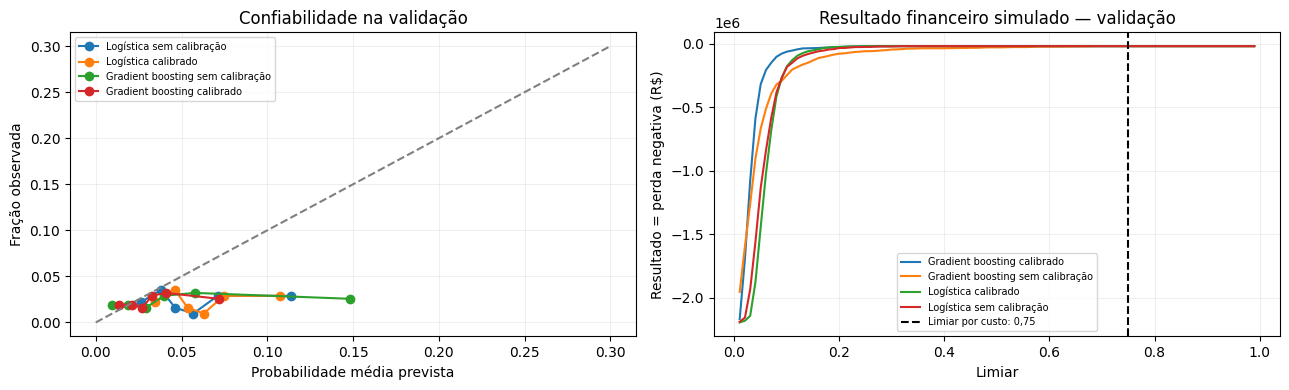

In [3]:
from sklearn.calibration import calibration_curve
dval = partes['validacao']
fig,eixos = plt.subplots(1,2,figsize=(13,4))
curvas=[]
for nome in ['Logística sem calibração','Logística calibrado','Gradient boosting sem calibração','Gradient boosting calibrado']:
    p = probabilidades['validacao'][nome]
    obs,prev = calibration_curve(dval.is_canceled,p,n_bins=6,strategy='quantile')
    eixos[0].plot(prev,obs,marker='o',label=nome)
    for limiar in np.linspace(0.01,0.99,99):
        custo = custo_classificacao(dval.is_canceled,p>=limiar).sum()
        curvas.append({'modelo':nome,'limiar':limiar,'custo':custo})
eixos[0].plot([0,0.3],[0,0.3],ls='--',color='gray');eixos[0].legend(fontsize=7)
eixos[0].set(xlabel='Probabilidade média prevista',ylabel='Fração observada',title='Confiabilidade na validação')
curvas=pd.DataFrame(curvas)
for nome,g in curvas.groupby('modelo'):
    eixos[1].plot(g.limiar, -g.custo,label=nome)
eixos[1].axvline(LIMIAR,ls='--',color='black',label='Limiar por custo: 0,75')
eixos[1].set(xlabel='Limiar',ylabel='Resultado = perda negativa (R$)',title='Resultado financeiro simulado — validação')
eixos[1].legend(fontsize=7);plt.tight_layout();plt.show()
curvas.to_csv(RAIZ / 'resultados/curva_financeira_validacao.csv',index=False)

**Leitura:** quanto menos negativo o resultado financeiro, menor a perda
incremental. A curva não mede receita do hotel. O ponto 0,75 continua sendo a
decisão teórica sob probabilidades calibradas; um ótimo empírico diferente
pode decorrer de ruído ou má calibração. Confiabilidade ruim em probabilidades
baixas já preocupa; poucos casos em probabilidades altas impedem validar
com precisão a região do limiar. Não basta ter AUC alta.

## 4. Teste final da política congelada

Agora abrimos março a agosto de 2017. As demais linhas são referências diagnósticas, não uma nova seleção de modelo.

,parte,n,eventos_positivos,ROC_AUC,PR_AUC_AP,Brier,precisao,recall,revendas,FP,FN,TP,TN,custo_total,custo_por_reserva
modelo,,,,,,,,,,,,,,,
Nunca revender,teste,12488,231,0.5000,0.0185,0.0185,0.0000,0.0000,0,0,231,0,12257,"92,400.0000",7.3991
Prevalência treino,teste,12488,231,0.5000,0.0185,0.0183,0.0000,0.0000,0,0,231,0,12257,"92,400.0000",7.3991
Regra lead ≥90,teste,12488,231,0.5567,0.0210,0.0182,0.0000,0.0000,0,0,231,0,12257,"92,400.0000",7.3991
Logística sem calibração,teste,12488,231,0.5782,0.0292,0.0185,0.0000,0.0000,0,0,231,0,12257,"92,400.0000",7.3991
Logística calibrado,teste,12488,231,0.5782,0.0292,0.0187,0.0000,0.0000,0,0,231,0,12257,"92,400.0000",7.3991
Gradient boosting sem calibração,teste,12488,231,0.5670,0.0341,0.0185,0.0000,0.0000,0,0,231,0,12257,"92,400.0000",7.3991
Gradient boosting calibrado,teste,12488,231,0.5670,0.0341,0.0181,0.0000,0.0000,0,0,231,0,12257,"92,400.0000",7.3991


,Não revende,Revende
Chega,12257,0
Não chega,231,0


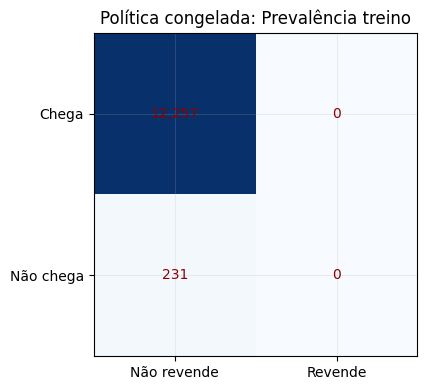

In [4]:
teste_a = tabela.loc[tabela.parte.eq('teste')].set_index('modelo')
display(teste_a)
dteste = partes['teste'].copy()
pteste = probabilidades['teste'][vencedor_a]
dteste['probabilidade'] = pteste
dteste['revender'] = (pteste >= LIMIAR).astype(int)
dteste['custo'] = custo_classificacao(dteste.is_canceled,dteste.revender)
dteste['custo_nunca_revender'] = CUSTO_FN * dteste.is_canceled
matriz = confusion_matrix(dteste.is_canceled,dteste.revender,labels=[0,1])
display(pd.DataFrame(matriz,index=['Chega','Não chega'],columns=['Não revende','Revende']))
fig,ax=plt.subplots(figsize=(6,4));ax.imshow(matriz,cmap='Blues')
for i in range(2):
    for j in range(2):ax.text(j,i,f'{matriz[i,j]:,}',ha='center',va='center',color='darkred')
ax.set_xticks([0,1],['Não revende','Revende']);ax.set_yticks([0,1],['Chega','Não chega'])
ax.set_title('Política congelada: '+vencedor_a);plt.tight_layout();plt.show()
dteste[['id_linha','data_chegada','is_canceled','data_rotulo','probabilidade','revender','custo','custo_nunca_revender']].to_csv(
    RAIZ / 'resultados/classificacao_teste_eventos.csv',index=False)

**Leitura:** revender quando o titular chega é o erro de R$ 1.200; não revender
quando ele falta é o erro de R$ 400. A tabela permite ver se um modelo com
ranking melhor realmente muda a ação. Se nenhuma probabilidade alcançar 0,75,
o modelo e a política “nunca revender” terão o mesmo custo: não há economia
incremental comprovada só por prever melhor o risco.

## 5. Estabilidade mensal e sensibilidade

Uma média pode esconder meses ruins. A análise de sensibilidade altera hipóteses de custo na política congelada, sem retreinar ou escolher um novo modelo no teste.

In [5]:
mensal = dteste.groupby(dteste.data_chegada.dt.to_period('M')).agg(
    reservas=('id_linha','size'), positivos=('is_canceled','sum'),
    revendas=('revender','sum'), custo=('custo','sum'),
    custo_baseline=('custo_nunca_revender','sum'))
mensal['custo_por_reserva'] = mensal.custo/mensal.reservas
mensal['economia_vs_baseline'] = mensal.custo_baseline-mensal.custo
display(mensal)
sensibilidade=[]
for caro in [400,800,1200,2000]:
    t = caro/(caro+CUSTO_FN)
    perdas = custo_classificacao(dteste.is_canceled,pteste>=t,caro,CUSTO_FN)
    sensibilidade.append({'custo_FP':caro,'custo_FN':CUSTO_FN,'limiar':t,
        'revendas':int((pteste>=t).sum()),'perda_simulada':perdas.sum()})
display(pd.DataFrame(sensibilidade))
resumo_a = {'vencedor':vencedor_a,'limiar':LIMIAR,
    'validacao':validacao_a.reset_index().to_dict('records'),
    'teste':teste_a.reset_index().to_dict('records'),
    'custo_teste':float(dteste.custo.sum()),
    'baseline_teste':float(dteste.custo_nunca_revender.sum()),
    'economia':float(dteste.custo_nunca_revender.sum()-dteste.custo.sum()),
    'revendas':int(dteste.revender.sum()),'n_teste':len(dteste),
    'positivos_teste':int(dteste.is_canceled.sum()),
    'desvio_custo_mensal_por_reserva':float(mensal.custo_por_reserva.std())}
salvar_json('resumo_a.json',resumo_a)
mensal.to_csv(RAIZ/'resultados/classificacao_mensal.csv')

,reservas,positivos,revendas,custo,custo_baseline,custo_por_reserva,economia_vs_baseline
data_chegada,,,,,,,
2017-03,2050,47,0,"18,800.0000","18,800.0000",9.1707,0.0000
2017-04,1959,26,0,"10,400.0000","10,400.0000",5.3088,0.0000
2017-05,2298,62,0,"24,800.0000","24,800.0000",10.7920,0.0000
2017-06,2111,36,0,"14,400.0000","14,400.0000",6.8214,0.0000
2017-07,2208,29,0,"11,600.0000","11,600.0000",5.2536,0.0000
2017-08,1862,31,0,"12,400.0000","12,400.0000",6.6595,0.0000


,custo_FP,custo_FN,limiar,revendas,perda_simulada
0,400,400.0000,0.5000,0,"92,400.0000"
1,800,400.0000,0.6667,0,"92,400.0000"
2,1200,400.0000,0.7500,0,"92,400.0000"
3,2000,400.0000,0.8333,0,"92,400.0000"


**Leitura:** custos mensais totais variam também com o volume. O custo por
reserva ajuda a comparar meses, mas não torna os eventos independentes.
Não temos identificação de grupos ou clientes para estimar toda a dependência.
A sensibilidade é um cenário contrafactual de perdas, não nova evidência
experimental. A calibragem de novembro/dezembro pode envelhecer; essa é uma
limitação do congelamento, a ser monitorada antes de qualquer uso real.

<!-- RESULTADOS_A2 -->

## Recomendação final

A seleção por custo, com Brier como desempate, escolheu **Prevalência treino**.
Todas as alternativas tiveram a mesma perda na validação no limiar de 0,75.
No teste de **12.488 reservas**, com **231**
cancelamentos tardios/no-shows, a política escolhida fez **0 revendas**.
Sua perda simulada foi **R$ 92.400,00**, idêntica à de nunca revender:
**economia incremental de R$ 0,00**. Precisão e recall da ação são
zero, pois nenhum caso cruza o limiar. Isso é uma decisão conservadora, não
identificação bem-sucedida dos faltantes.

Os rankings dos modelos flexíveis foram fracos no período: ROC-AUC de
0,578 na logística e
0,567 no boosting.
O desvio entre os seis meses do custo por reserva foi
R$ 2,21; é uma descrição da variabilidade,
não um intervalo de confiança. Agosto tem apenas 29 dias no teste comum a A e B.

**Para a gestão:** mantenha a política sem revenda automática nesta população.
Não há economia demonstrada que sustente adicionar o modelo à decisão.
Registre o custo de oportunidades perdidas e os casos de não comparecimento.
Antes de outro piloto, obtenha snapshots históricos, demanda de reposição,
inventário e custos reais. Preserve o limiar como função dos custos; não o reduza
até conseguir uma recomendação positiva.

O recorte é deliberadamente estreito: os cancelamentos anteriores à véspera
podem ser tratados por uma operação de inventário conhecida, mas estão fora
do risco aqui modelado. Este resultado não demonstra que todo problema de
cancelamento de hotéis seja imprevisível.

## Referência técnica

[scikit-learn — calibração de probabilidades](https://scikit-learn.org/stable/modules/calibration.html).
A separação temporal de calibração foi implementada explicitamente, sem
validação cruzada aleatória. O código usa as versões fixadas nas dependências.